In [11]:
x=1

In [12]:
import scanpy as sc
import numpy as np
import seaborn as sns
import squidpy as sq
import pandas as pd
import matplotlib.pyplot as plt

import matplotlib
matplotlib.rcParams['figure.figsize'] = [6, 4]
matplotlib.rcParams['figure.dpi'] = 300
sc.set_figure_params(vector_friendly=True)

In [39]:
adata = sc.read('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil/imc_grade/df81fb9f2d_adata_analysis_annotated.h5ad')
adata

AnnData object with n_obs × n_vars = 374964 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [40]:
# Define consistent color palette for all plots
import matplotlib.colors as mcolors

def create_color_palette(adata, cluster_key='cluster_preprocessed'):
    """Create a consistent color palette for all cell types using tab10"""
    unique_celltypes = list(adata.obs[cluster_key].cat.categories)
    
    # Use tab10 color palette - 10 distinct colors
    colors_tab10 = plt.cm.tab10(np.linspace(0, 1, 10))  # tab10 has 10 colors
    
    # If we need more colors, extend with tab20
    if len(unique_celltypes) > 10:
        colors_tab20 = plt.cm.tab20(np.linspace(0, 1, 20))
        all_colors = np.vstack([colors_tab10, colors_tab20[10:]])  # Use tab20 colors 11-20
    else:
        all_colors = colors_tab10
    
    # Create color dictionary
    color_dict = {}
    for i, celltype in enumerate(unique_celltypes):
        color_dict[celltype] = all_colors[i % len(all_colors)]
    
    return color_dict

# Create color palette
CELL_TYPE_COLORS = create_color_palette(adata, 'cluster_preprocessed')

In [41]:
colors_tab10 = plt.cm.tab10(np.linspace(0, 1, 10))
CELL_TYPE_COLORS['top tumor cells'] = colors_tab10[7]

In [42]:
print("Color palette created for cell types:")
for celltype, color in CELL_TYPE_COLORS.items():
    print(f"  {celltype}: {mcolors.to_hex(color)}")

Color palette created for cell types:
  B cells: #1f77b4
  T and B cells: #ff7f0e
  T cells: #2ca02c
  endothelial: #d62728
  macrophages: #9467bd
  stromal cells: #8c564b
  tumor cells: #e377c2
  top tumor cells: #7f7f7f


In [43]:
adata = adata[~adata.obs['cluster_preprocessed'].isna()].copy()
adata

AnnData object with n_obs × n_vars = 359171 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [44]:
def plot_tumor_cells_cooccurrence_across_slides(adata, slide_key, cluster_key, intervals, filter_for=None, save_name=None):
    occ = []
    for sample in np.unique(adata.obs[slide_key]):
        adata_tmp = adata[adata.obs[slide_key] == sample].copy()
        sq.gr.spatial_neighbors(adata_tmp)
        sq.gr.co_occurrence(adata_tmp, cluster_key=cluster_key, interval=intervals)

        if filter_for is not None:
            if filter_for in adata_tmp.obs[cluster_key].cat.categories:
                idx = np.where(adata_tmp.obs[cluster_key].cat.categories == filter_for)[0][0]
                df = pd.DataFrame(adata_tmp.uns[f'{cluster_key}_co_occurrence']['occ'][idx, :, :], index=adata_tmp.obs[cluster_key].cat.categories).T
                occ.append(df)
        
    occs = pd.concat(occ, axis=0, keys=range(len(occ)))
    mean = occs.groupby(level=1).mean()

    plt.figure(figsize=(6, 4))
    x = mean.index  # 68 intervals

    for col in mean.columns:
        # Use consistent colors from the global color palette
        color = CELL_TYPE_COLORS.get(col, '#1f77b4')  # Default blue if not found
        plt.plot(x, mean[col], label=col, color=color)

    # plt.xlabel("Interval")
    # plt.ylabel("Value")
    plt.title("Mean for each cell type")
    plt.legend(title="Cell type")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_name is not None:
        plt.savefig(save_name, dpi=300, bbox_inches='tight')
    plt.show()

## all slides

In [45]:
intervals = np.arange(5, 350, 5)

In [46]:
len(intervals)

69

100%|██████████| 1/1 [00:00<00:00,  1.71/s]

100%|██████████| 1/1 [00:00<00:00,  2.04/s]

100%|██████████| 1/1 [00:00<00:00,  1.60/s]

100%|██████████| 1/1 [00:00<00:00,  1.49/s]

100%|██████████| 1/1 [00:00<00:00,  1.59/s]

100%|██████████| 1/1 [00:00<00:00,  4.72/s]

100%|██████████| 1/1 [00:00<00:00,  4.60/s]

100%|██████████| 1/1 [00:00<00:00,  3.45/s]

100%|██████████| 1/1 [00:02<00:00,  2.25s/]

100%|██████████| 1/1 [00:01<00:00,  1.05s/]

100%|██████████| 1/1 [00:01<00:00,  1.05s/]

100%|██████████| 1/1 [00:01<00:00,  1.03s/]

100%|██████████| 1/1 [00:01<00:00,  1.46s/]

100%|██████████| 1/1 [00:00<00:00,  1.16/s]

100%|██████████| 1/1 [00:00<00:00,  1.10/s]

100%|██████████| 1/1 [00:01<00:00,  1.06s/]

100%|██████████| 1/1 [00:00<00:00,  1.24/s]

100%|██████████| 1/1 [00:00<00:00,  3.13/s]

100%|██████████| 1/1 [00:00<00:00,  1.99/s]

100%|██████████| 1/1 [00:00<00:00,  2.33/s]

100%|██████████| 1/1 [00:00<00:00,  3.59/s]

100%|██████████| 1/1 [00:00<00:00,  1.76/s]

100%|█████

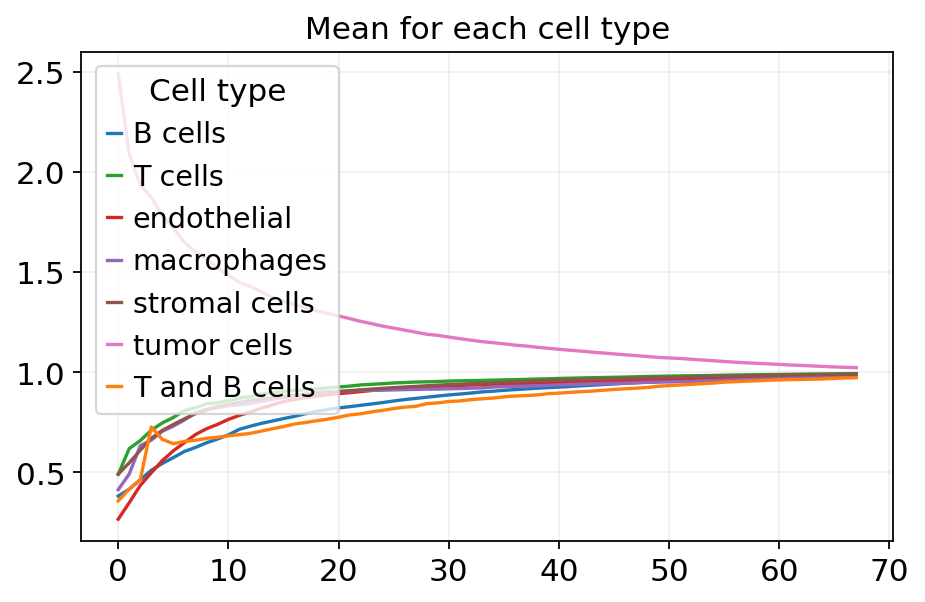

In [47]:
plot_tumor_cells_cooccurrence_across_slides(adata, 'core', 'cluster_preprocessed', intervals, filter_for='tumor cells', save_name='figures/tumor_cells_cooccurrence_across_slides.svg')

## after splitting into top and not top tumor cells

In [48]:
def score_top_cells(adata, sample_key, top_fraction=0.1, key_added='top_cell_attn'):
    adata.obs[key_added] = False
    for sample in np.unique(adata.obs[sample_key]):
        adata_sample = adata[adata.obs[sample_key] == sample].copy()
        threshold_idx = int(len(adata_sample) * 0.9)
        threshold_value = sorted(adata_sample.obs['cell_attn'])[threshold_idx]
        top_idx = adata_sample[adata_sample.obs['cell_attn'] >= threshold_value].obs_names
        adata.obs.loc[top_idx, 'top_cell_attn'] = True
    adata.obs[key_added] = adata.obs[key_added].astype('category')

In [49]:
score_top_cells(adata, sample_key='core')

In [50]:
adata.obs['top_cell_attn']

id
ZTMA208_slide_36_By6x6_437     False
ZTMA208_slide_51_Ay6x8_830     False
ZTMA208_slide_53_By11x6_754    False
ZTMA208_slide_38_By4x7_801     False
ZTMA208_slide_16_Ay16x4_149    False
                               ...  
ZTMA208_slide_40_By7x4_1171    False
ZTMA208_slide_1_Ay12x5_715     False
ZTMA208_slide_9_By4x2_934      False
ZTMA208_slide_67_Ay14x6_680    False
ZTMA208_slide_22_Cy10x1_632    False
Name: top_cell_attn, Length: 359171, dtype: category
Categories (2, bool): [False, True]

In [51]:
adata.obs['celltype'] = adata.obs['cluster_preprocessed'].copy()
adata.obs['celltype'] = adata.obs['celltype'].astype(str)
adata.obs.loc[(adata.obs['cluster_preprocessed'] == 'tumor cells') & (adata.obs['top_cell_attn'] == True), 'celltype'] = 'top tumor cells'
adata.obs['celltype'] = adata.obs['celltype'].astype('category')

adata.obs['celltype'].cat.categories

Index(['B cells', 'T and B cells', 'T cells', 'endothelial', 'macrophages',
       'stromal cells', 'top tumor cells', 'tumor cells'],
      dtype='object')


100%|██████████| 1/1 [00:00<00:00,  1.66/s]




100%|██████████| 1/1 [00:00<00:00,  1.93/s]




100%|██████████| 1/1 [00:00<00:00,  1.48/s]




100%|██████████| 1/1 [00:00<00:00,  1.50/s]




100%|██████████| 1/1 [00:00<00:00,  1.57/s]




100%|██████████| 1/1 [00:00<00:00,  4.70/s]




100%|██████████| 1/1 [00:00<00:00,  4.93/s]




100%|██████████| 1/1 [00:00<00:00,  3.40/s]




100%|██████████| 1/1 [00:02<00:00,  2.22s/]




100%|██████████| 1/1 [00:01<00:00,  1.06s/]




100%|██████████| 1/1 [00:01<00:00,  1.02s/]




100%|██████████| 1/1 [00:00<00:00,  1.02/s]




100%|██████████| 1/1 [00:01<00:00,  1.43s/]




100%|██████████| 1/1 [00:00<00:00,  1.17/s]




100%|██████████| 1/1 [00:00<00:00,  1.10/s]




100%|██████████| 1/1 [00:00<00:00,  5.14/s]

100%|██████████| 1/1 [00:00<00:00,  5.14/s]



100%|██████████| 1/1 [00:01<00:00,  1.04s/]




100%|██████████| 1/1 [00:00<00:00,  1.19/s]




100%|██████████| 1/1 [00:00<00:00,  3.05/s]




100%|██████████| 1/1 [00:00<00:00,  5.01/s]

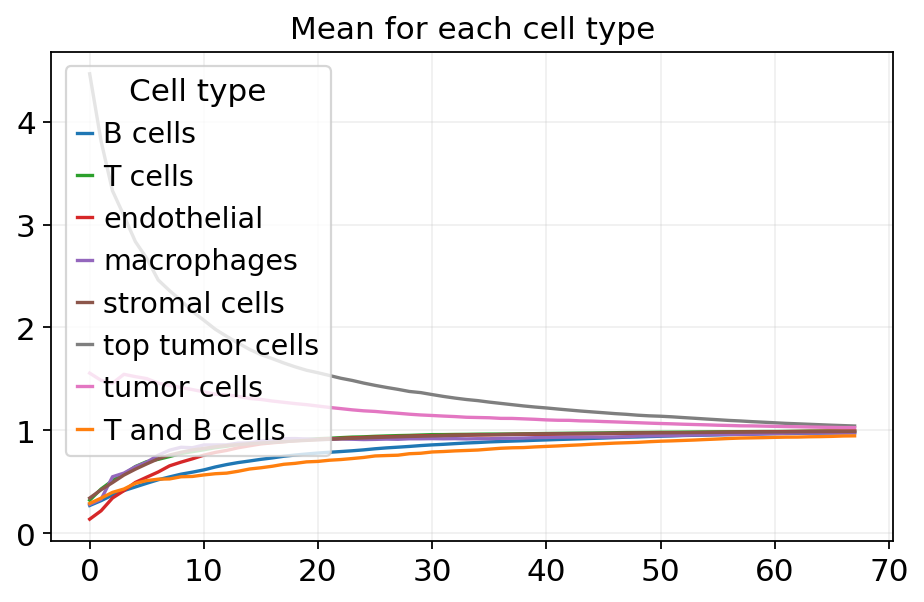

In [53]:
plot_tumor_cells_cooccurrence_across_slides(adata, 'core', 'celltype', intervals, filter_for='top tumor cells', save_name='figures/top_tumor_cells_cooccurrence_across_slides.svg')

## same plots as above but split by grade

In [54]:
adata_grade1 = adata[adata.obs['grade'] == '1'].copy()
adata_grade2 = adata[adata.obs['grade'] == '2'].copy()
adata_grade3 = adata[adata.obs['grade'] == '3'].copy()


100%|██████████| 1/1 [00:00<00:00,  2.86/s]




100%|██████████| 1/1 [00:01<00:00,  1.13s/]




100%|██████████| 1/1 [00:01<00:00,  1.11s/]




100%|██████████| 1/1 [00:00<00:00,  2.89/s]




100%|██████████| 1/1 [00:00<00:00,  1.12/s]



100%|██████████| 1/1 [00:00<00:00, 12.18/s]




100%|██████████| 1/1 [00:00<00:00,  4.44/s]




100%|██████████| 1/1 [00:00<00:00,  1.69/s]




100%|██████████| 1/1 [00:00<00:00,  1.43/s]




100%|██████████| 1/1 [00:01<00:00,  1.05s/]




100%|██████████| 1/1 [00:00<00:00,  1.16/s]




100%|██████████| 1/1 [00:01<00:00,  1.48s/]




100%|██████████| 1/1 [00:00<00:00,  1.12/s]




100%|██████████| 1/1 [00:00<00:00,  2.75/s]




100%|██████████| 1/1 [00:01<00:00,  1.35s/]




100%|██████████| 1/1 [00:01<00:00,  1.38s/]




100%|██████████| 1/1 [00:01<00:00,  1.14s/]




100%|██████████| 1/1 [00:01<00:00,  1.95s/]




100%|██████████| 1/1 [00:01<00:00,  1.66s/]




100%|██████████| 1/1 [00:00<00:00,  1.15/s]




100%|██████████| 1/1 [00:01<00:00,  1.22

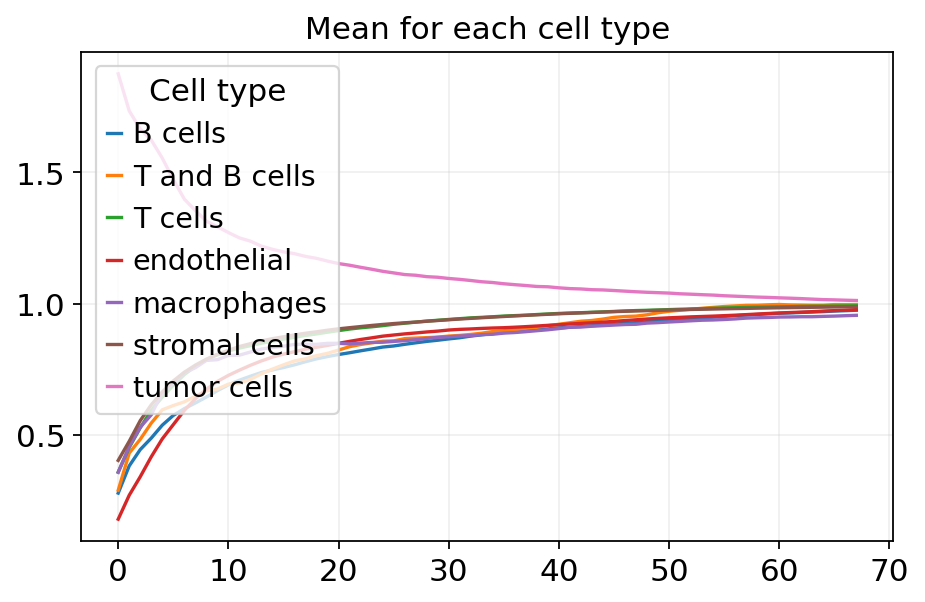

In [55]:
plot_tumor_cells_cooccurrence_across_slides(adata_grade1, slide_key='core', cluster_key='cluster_preprocessed', intervals=intervals, filter_for='tumor cells', save_name='figures/tumor_cells_cooccurrence_across_slides_grade1.svg')

100%|██████████| 1/1 [00:00<00:00,  1.73/s]




100%|██████████| 1/1 [00:00<00:00,  1.97/s]




100%|██████████| 1/1 [00:00<00:00,  1.53/s]




100%|██████████| 1/1 [00:00<00:00,  1.53/s]




100%|██████████| 1/1 [00:00<00:00,  1.56/s]




100%|██████████| 1/1 [00:00<00:00,  4.72/s]




100%|██████████| 1/1 [00:00<00:00,  4.64/s]




100%|██████████| 1/1 [00:00<00:00,  3.54/s]




100%|██████████| 1/1 [00:02<00:00,  2.12s/]




100%|██████████| 1/1 [00:01<00:00,  1.06s/]




100%|██████████| 1/1 [00:01<00:00,  1.03s/]




100%|██████████| 1/1 [00:00<00:00,  3.03/s]




100%|██████████| 1/1 [00:00<00:00,  4.24/s]




100%|██████████| 1/1 [00:00<00:00,  1.63/s]




100%|██████████| 1/1 [00:00<00:00,  2.33/s]




100%|██████████| 1/1 [00:00<00:00,  3.41/s]




100%|██████████| 1/1 [00:00<00:00,  1.71/s]




100%|██████████| 1/1 [00:00<00:00,  1.68/s]




100%|██████████| 1/1 [00:00<00:00,  1.09/s]




100%|██████████| 1/1 [00:01<00:00,  1.13s/]




100%|██████████| 1/1 [00:00<00:00,  1.50

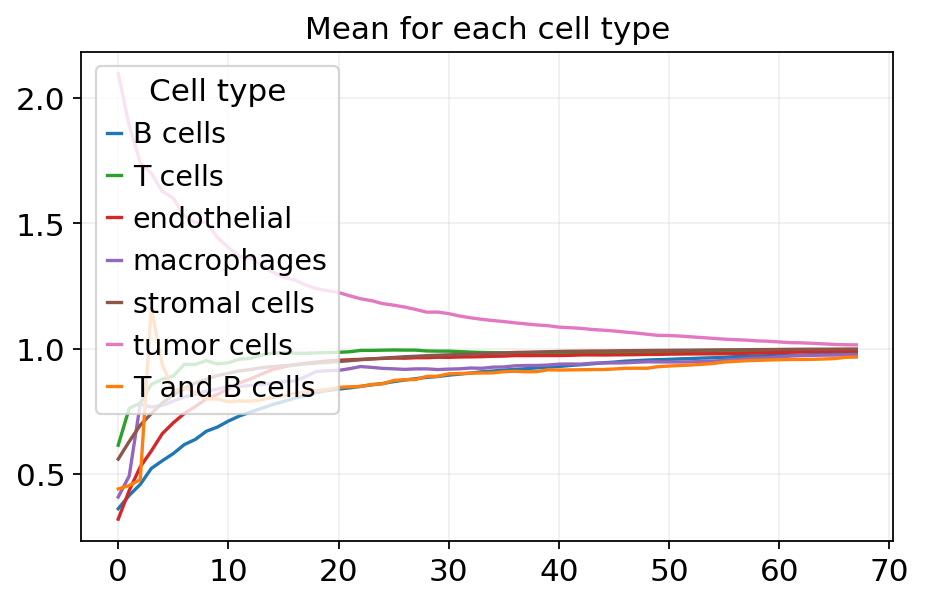

In [56]:
plot_tumor_cells_cooccurrence_across_slides(adata_grade2, slide_key='core', cluster_key='cluster_preprocessed', intervals=intervals, filter_for='tumor cells', save_name='figures/tumor_cells_cooccurrence_across_slides_grade2.svg')


100%|██████████| 1/1 [00:01<00:00,  1.01s/]




100%|██████████| 1/1 [00:01<00:00,  1.47s/]




100%|██████████| 1/1 [00:00<00:00,  1.16/s]




100%|██████████| 1/1 [00:00<00:00,  1.08/s]




100%|██████████| 1/1 [00:00<00:00,  4.49/s]




100%|██████████| 1/1 [00:01<00:00,  1.09s/]




100%|██████████| 1/1 [00:00<00:00,  1.17/s]




100%|██████████| 1/1 [00:01<00:00,  1.88s/]




100%|██████████| 1/1 [00:01<00:00,  1.95s/]




100%|██████████| 1/1 [00:01<00:00,  1.46s/]




100%|██████████| 1/1 [00:01<00:00,  1.06s/]




100%|██████████| 1/1 [00:01<00:00,  1.54s/]





100%|██████████| 1/1 [00:01<00:00,  1.90s/]





100%|██████████| 1/1 [00:01<00:00,  1.86s/]




100%|██████████| 1/1 [00:02<00:00,  2.45s/]




100%|██████████| 1/1 [00:01<00:00,  1.21s/]




100%|██████████| 1/1 [00:00<00:00,  6.99/s]




100%|██████████| 1/1 [00:01<00:00,  1.14s/]




100%|██████████| 1/1 [00:01<00:00,  1.24s/]




100%|██████████| 1/1 [00:00<00:00,  1.11/s]




100%|██████████| 1/1 [00:01<00:00,  1.15s/]




100%|██████████| 1/1 [00:00<00:00,  1.11/s]




100%|██████████| 1/1 [00:00<00:00,  1.54/s]




100%|██████████| 1/1 [00:04<00:00,  4.84s/]




100%|██████████| 1/1 [00:01<00:00,  1.72s/]




100%|██████████| 1/1 [00:05<00:00,  5.09s/]




100%|██████████| 1/1 [00:05<00:00,  5.54s/]




100%|██████████| 1/1 [00:00<00:00,  1.19/s]




100%|██████████| 1/1 [00:00<00:00,  1.17/s]




100%|██████████| 1/1 [00:01<00:00,  1.12s/]




100%|██████████| 1/1 [00:00<00:00,  1.22/s]




100%|██████████| 1/1 [00:00<00:00,  1.10/s]




100%|██████████| 1/1 [00:00<00:00,  1.1

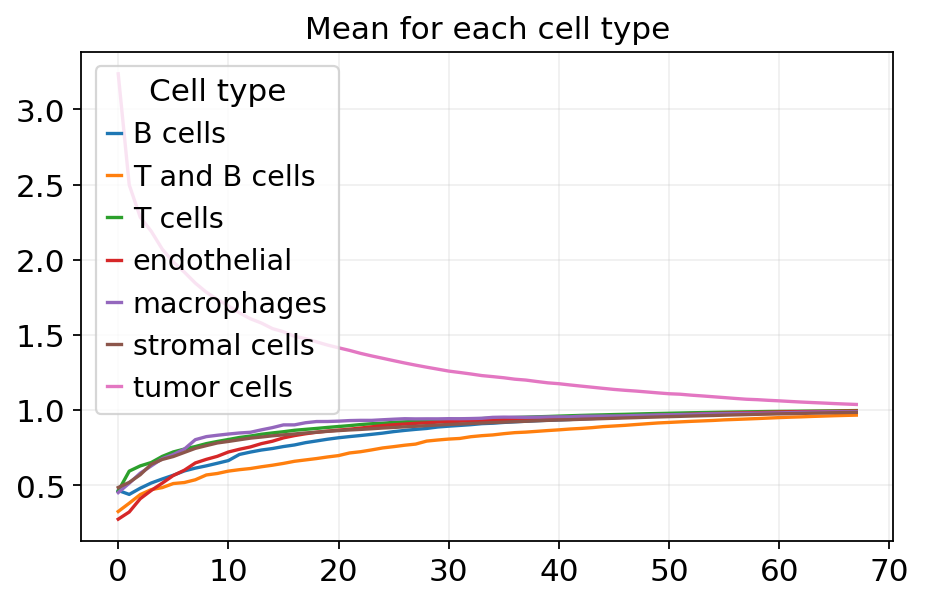

In [57]:
plot_tumor_cells_cooccurrence_across_slides(adata_grade3, slide_key='core', cluster_key='cluster_preprocessed', intervals=intervals, filter_for='tumor cells', save_name='figures/tumor_cells_cooccurrence_across_slides_grade3.svg')


100%|██████████| 1/1 [00:00<00:00,  2.62/s]




100%|██████████| 1/1 [00:01<00:00,  1.17s/]




100%|██████████| 1/1 [00:01<00:00,  1.16s/]




100%|██████████| 1/1 [00:00<00:00,  2.62/s]




100%|██████████| 1/1 [00:00<00:00,  1.04/s]



100%|██████████| 1/1 [00:00<00:00, 10.73/s]




100%|██████████| 1/1 [00:00<00:00,  3.85/s]




100%|██████████| 1/1 [00:00<00:00,  1.62/s]




100%|██████████| 1/1 [00:00<00:00,  1.38/s]




100%|██████████| 1/1 [00:01<00:00,  1.07s/]




100%|██████████| 1/1 [00:00<00:00,  1.11/s]




100%|██████████| 1/1 [00:01<00:00,  1.44s/]




100%|██████████| 1/1 [00:00<00:00,  1.07/s]




100%|██████████| 1/1 [00:00<00:00,  2.61/s]




100%|██████████| 1/1 [00:01<00:00,  1.35s/]




100%|██████████| 1/1 [00:01<00:00,  1.40s/]




100%|██████████| 1/1 [00:01<00:00,  1.13s/]




100%|██████████| 1/1 [00:01<00:00,  1.97s/]




100%|██████████| 1/1 [00:01<00:00,  1.68s/]




100%|██████████| 1/1 [00:00<00:00,  1.11/s]




100%|██████████| 1/1 [00:01<00:00,  1.24

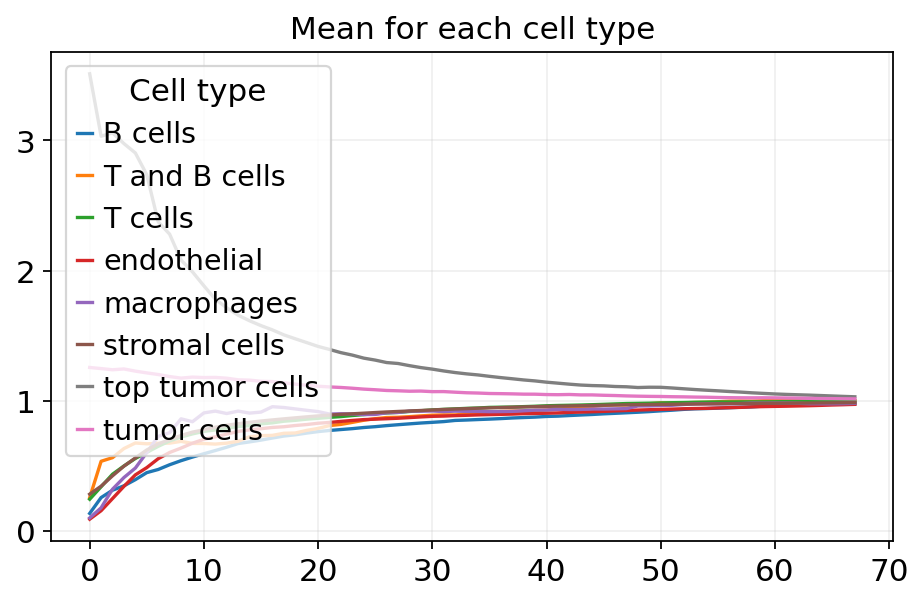

In [58]:
plot_tumor_cells_cooccurrence_across_slides(adata_grade1, 'core', 'celltype', intervals, filter_for='top tumor cells', save_name='figures/top_tumor_cells_cooccurrence_across_slides_grade1.svg')


100%|██████████| 1/1 [00:00<00:00,  1.67/s]




100%|██████████| 1/1 [00:00<00:00,  1.89/s]




100%|██████████| 1/1 [00:00<00:00,  1.47/s]




100%|██████████| 1/1 [00:00<00:00,  1.45/s]




100%|██████████| 1/1 [00:00<00:00,  1.54/s]




100%|██████████| 1/1 [00:00<00:00,  4.32/s]




100%|██████████| 1/1 [00:00<00:00,  4.22/s]




100%|██████████| 1/1 [00:00<00:00,  3.25/s]





100%|██████████| 1/1 [00:02<00:00,  2.22s/]




100%|██████████| 1/1 [00:01<00:00,  1.11s/]




100%|██████████| 1/1 [00:01<00:00,  1.04s/]




100%|██████████| 1/1 [00:00<00:00,  2.90/s]




100%|██████████| 1/1 [00:00<00:00,  4.44/s]




100%|██████████| 1/1 [00:00<00:00,  1.81/s]




100%|██████████| 1/1 [00:00<00:00,  2.24/s]




100%|██████████| 1/1 [00:00<00:00,  3.34/s]




100%|██████████| 1/1 [00:00<00:00,  1.70/s]




100%|██████████| 1/1 [00:00<00:00,  1.68/s]




100%|██████████| 1/1 [00:00<00:00,  1.05/s]




100%|██████████| 1/1 [00:01<00:00,  1.16s/]




100%|██████████| 1/1 [00:00<00:00,  1.45/s]




100%|██████████| 1/1 [00:00<00:00,  1.41/s]




100%|██████████| 1/1 [00:00<00:00,  1.41/s]




100%|██████████| 1/1 [00:01<00:00,  1.04s/]




100%|██████████| 1/1 [00:01<00:00,  1.01s/]




100%|██████████| 1/1 [00:00<00:00,  2.22/s]




100%|██████████| 1/1 [00:00<00:00,  1.25/s]




100%|██████████| 1/1 [00:00<00:00,  8.71/s]

100%|██████████| 1/1 [00:00<00:00,  8.71/s]

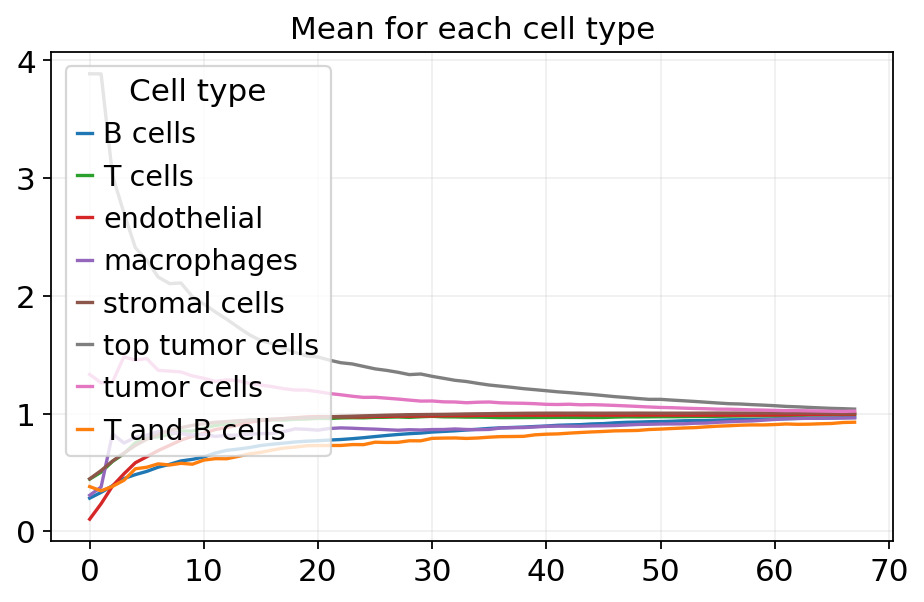

In [59]:
plot_tumor_cells_cooccurrence_across_slides(adata_grade2, 'core', 'celltype', intervals, filter_for='top tumor cells', save_name='figures/top_tumor_cells_cooccurrence_across_slides_grade2.svg')


100%|██████████| 1/1 [00:00<00:00,  1.01/s]




100%|██████████| 1/1 [00:01<00:00,  1.44s/]




100%|██████████| 1/1 [00:00<00:00,  1.17/s]


  0%|          | 0/1 [00:00<?, ?/s]

100%|██████████| 1/1 [00:00<00:00,  1.08/s]




100%|██████████| 1/1 [00:00<00:00,  4.55/s]




100%|██████████| 1/1 [00:01<00:00,  1.08s/]




100%|██████████| 1/1 [00:00<00:00,  1.18/s]




100%|██████████| 1/1 [00:01<00:00,  1.82s/]




100%|██████████| 1/1 [00:01<00:00,  1.91s/]




100%|██████████| 1/1 [00:01<00:00,  1.40s/]




100%|██████████| 1/1 [00:01<00:00,  1.03s/]




100%|██████████| 1/1 [00:01<00:00,  1.55s/]




100%|██████████| 1/1 [00:01<00:00,  1.84s/]




100%|██████████| 1/1 [00:01<00:00,  1.83s/]




100%|██████████| 1/1 [00:02<00:00,  2.46s/]




100%|██████████| 1/1 [00:01<00:00,  1.17s/]




100%|██████████| 1/1 [00:00<00:00,  7.81/s]




100%|██████████| 1/1 [00:01<00:00,  1.11s/]




100%|██████████| 1/1 [00:01<00:00,  1.21s/]




100%|██████████| 1/1 [00:00<00:00,  1.12/s]




100%

100%|██████████| 1/1 [00:00<00:00,  1.09/s]




100%|██████████| 1/1 [00:02<00:00,  2.22s/]




100%|██████████| 1/1 [00:01<00:00,  1.15s/]




100%|██████████| 1/1 [00:00<00:00,  2.74/s]




100%|██████████| 1/1 [00:00<00:00,  4.60/s]




100%|██████████| 1/1 [00:00<00:00,  2.88/s]




100%|██████████| 1/1 [00:02<00:00,  2.33s/]




100%|██████████| 1/1 [00:00<00:00,  1.90/s]




100%|██████████| 1/1 [00:00<00:00,  3.31/s]




100%|██████████| 1/1 [00:01<00:00,  1.59s/]




100%|██████████| 1/1 [00:00<00:00,  2.99/s]




100%|██████████| 1/1 [00:01<00:00,  1.81s/]




100%|██████████| 1/1 [00:02<00:00,  2.34s/]




100%|██████████| 1/1 [00:03<00:00,  3.23s/]




100%|██████████| 1/1 [00:01<00:00,  1.37s/]




100%|██████████| 1/1 [00:00<00:00,  1.06/s]




100%|██████████| 1/1 [00:02<00:00,  2.00s/]




100%|██████████| 1/1 [00:01<00:00,  1.35s/]




100%|██████████| 1/1 [00:00<00:00,  2.71/s]




100%|██████████| 1/1 [00:00<00:00,  1.30/s]




100%|██████████| 1/1 [00:00<00:00,  1.03

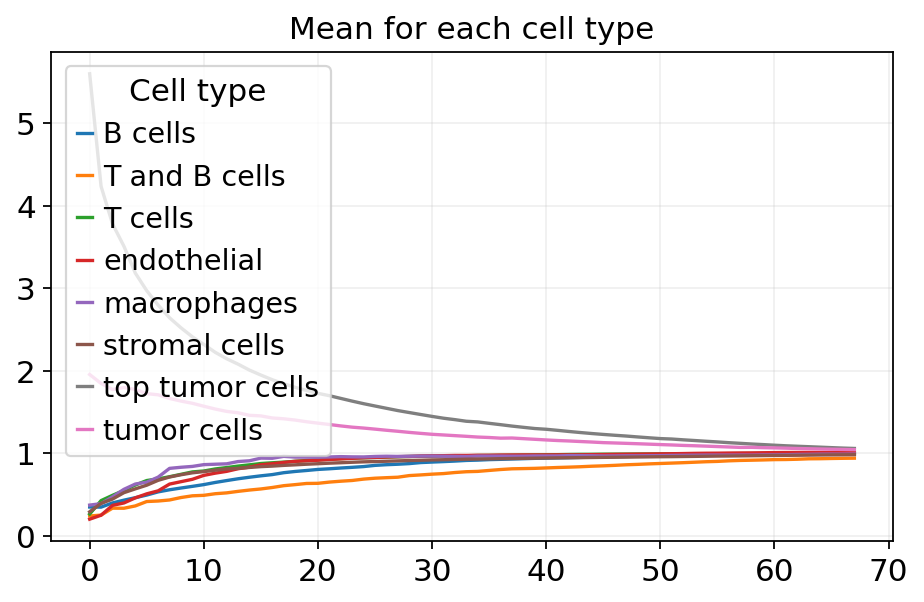

In [60]:
plot_tumor_cells_cooccurrence_across_slides(adata_grade3, 'core', 'celltype', intervals, filter_for='top tumor cells', save_name='figures/top_tumor_cells_cooccurrence_across_slides_grade3.svg')